<a href="https://colab.research.google.com/github/Adewol3/Africa-Technology-Forum-AI-Series-Week-1/blob/main/Practice_AFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

#Set random seed for reproducibilty
np.random.seed(42)

print("Libraries loaded successfully")

Libraries loaded successfully


Activity Probabilites
 Sleep: 20.00%
 Work: 40.00%
 Exercise: 13.33%
 Social: 13.33%
 Leisure: 13.33%


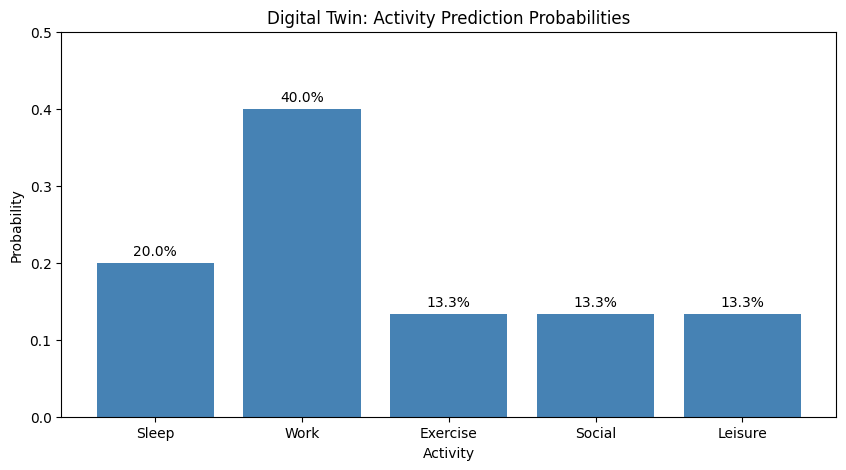

In [3]:
from collections import Counter

historical_activities = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]

def calculate_probabilities(sequence):
  """
  Calculate probability distribution from a sequence.
  Args:
    sequence: List of integers representing activities
  Returns:
    dict: Probability of each activity
  """

  counts = Counter(sequence)
  total = len(sequence)
  probabilities = {activity: count/total for activity, count in counts.items()}
  return probabilities

#Calculate probabilites
probs = calculate_probabilities(historical_activities)

#Display results
activity_names = {0:'Sleep', 1:'Work', 2:'Exercise', 3: 'Social', 4: 'Leisure'}
print("Activity Probabilites")
for activity, prob in  sorted(probs.items()):
  print(f" {activity_names[activity]}: {prob:.2%}")

#Visualize
plt.figure(figsize=(10,5))
activities = [activity_names[k] for k in sorted(probs.keys())]
probabilities = [probs[k] for k in sorted(probs.keys())]
plt.bar(activities, probabilities, color='steelblue')
plt.title('Digital Twin: Activity Prediction Probabilities')
plt.ylabel('Probability')
plt.xlabel('Activity')
plt.ylim(0, 0.5)
for i, v in enumerate(probabilities):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.show()

In [9]:
# Exercise 1.1 (Easy): Understanding Probabilities
# Task: Modify the historical activities to represent your own daily routine for 2 weeks (14 days).

# Create your own sequence of activities (14 values)
my_activities = [0, 1, 1, 1, 1, 1, 2, 0, 1, 1, 1, 1, 1, 4]  # 14 days of activities

# Calculate probabilities using your function from earlier
my_probs = calculate_probabilities(my_activities)

# Display results
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}
print("My Activity Probabilities:")
for activity, prob in sorted(my_probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

print(f'{my_probs.items()}')
print("Here it is" ,my_probs)
print(type(my_probs))
print(type(my_probs.items()))


My Activity Probabilities:
  Sleep: 14.29%
  Work: 71.43%
  Exercise: 7.14%
  Leisure: 7.14%
dict_items([(0, 0.14285714285714285), (1, 0.7142857142857143), (2, 0.07142857142857142), (4, 0.07142857142857142)])
Here it is {0: 0.14285714285714285, 1: 0.7142857142857143, 2: 0.07142857142857142, 4: 0.07142857142857142}
<class 'dict'>
<class 'dict_items'>


In [ ]:
def calculate_conditional_probabilities(sequence):
  transitions = {}

  for i in range(len(sequence) - 1):
    current = sequence[i]
    next_activity = sequence[i + 1]

    if current not in transitions:
      transitions[current] = []
      transitions[current].append(next_activity)

    #convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
      counts = Counter(next_list)
      total = len(next_list)
      conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs


# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")

Conditional Probabilities: P(Next | Current)

After Sleep:
  → Work: 100.00%


In [10]:
def calculate_conditional_probabilities(sequence):
    """
    Calculate P(next | current) - probability of next activity given current.

    Args:
        sequence: List of activities

    Returns:
        dict: Nested dictionary of conditional probabilities
    """
    transitions = {}

    for i in range(len(sequence) - 1):
        current = sequence[i]
        next_activity = sequence[i + 1]


        if current not in transitions:
            transitions[current] = []

            print('Before',transitions)

        transitions[current].append(next_activity)

        print('After',transitions)

    # Convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
        counts = Counter(next_list)
        total = len(next_list)
        conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs

# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")
    print()

Before {0: []}
After {0: [1]}
Before {0: [1], 1: []}
After {0: [1], 1: [2]}
Before {0: [1], 1: [2], 2: []}
After {0: [1], 1: [2], 2: [1]}
After {0: [1], 1: [2, 3], 2: [1]}
Before {0: [1], 1: [2, 3], 2: [1], 3: []}
After {0: [1], 1: [2, 3], 2: [1], 3: [1]}
After {0: [1], 1: [2, 3, 4], 2: [1], 3: [1]}
Before {0: [1], 1: [2, 3, 4], 2: [1], 3: [1], 4: []}
After {0: [1], 1: [2, 3, 4], 2: [1], 3: [1], 4: [0]}
After {0: [1, 1], 1: [2, 3, 4], 2: [1], 3: [1], 4: [0]}
After {0: [1, 1], 1: [2, 3, 4, 2], 2: [1], 3: [1], 4: [0]}
After {0: [1, 1], 1: [2, 3, 4, 2], 2: [1, 1], 3: [1], 4: [0]}
After {0: [1, 1], 1: [2, 3, 4, 2, 3], 2: [1, 1], 3: [1], 4: [0]}
After {0: [1, 1], 1: [2, 3, 4, 2, 3], 2: [1, 1], 3: [1, 1], 4: [0]}
After {0: [1, 1], 1: [2, 3, 4, 2, 3, 4], 2: [1, 1], 3: [1, 1], 4: [0]}
After {0: [1, 1], 1: [2, 3, 4, 2, 3, 4], 2: [1, 1], 3: [1, 1], 4: [0, 0]}
Conditional Probabilities: P(Next | Current)

After Sleep:
  → Work: 100.00%

After Work:
  → Exercise: 33.33%
  → Social: 33.33%
  → Leis

In [ ]:
def predict_next_activity(current_activity, conditional_probs):
    """
    Predict the most likely next activity.
    Args:
        current_activity: Current activity code
        conditional_probs: Dictionary of conditional probabilities
    Returns:
        int: Most likely next activity
    """
    if current_activity not in conditional_probs:
        return None

    next_probs = conditional_probs[current_activity]

    # Complete this function: Find the key with the maximum probability value
    # max() looks at the keys (activities), but uses the probability value as the comparison metric
    most_likely_next = max(next_probs, key=next_probs.get)

    return most_likely_next

# Test your function
current = 1  # Work
predicted = predict_next_activity(current, cond_probs)
print(f"After {activity_names[current]}, most likely next: {activity_names.get(predicted, 'Unknown')}")

# BONUS: Predict a sequence of 5 activities starting from "Work"
print("\nBonus: Predicted 5-step sequence starting from Work:")
sequence_steps = [current]
current_step = current

for _ in range(5):
    next_step = predict_next_activity(current_step, cond_probs)
    if next_step is None:
        break
    sequence_steps.append(next_step)
    current_step = next_step

# Print the sequence translated into human-readable names
readable_sequence = [activity_names[act] for act in sequence_steps]
print(" → ".join(readable_sequence))

After Work, most likely next: Exercise

Bonus: Predicted 5-step sequence starting from Work:
Work → Exercise → Work → Exercise → Work → Exercise


In [14]:
def sigmoid(x):
  return 1/(1+ np.exp(-x))

def perceptron(inputs, weights, bias):
  #Calculate weighted sum
  weighted_sum = np.dot(inputs, weights) + bias
  #Apply activation function
  output = sigmoid(weighted_sum)
  return output

person_features = np.array([7, 2, 0.8])  # 7 hours sleep, 2 hours free time, high energy

#Initialize random weights
weights = np.array([0.3,0.5,0.7])
bias = -0.5

prediction = perceptron(person_features, weights, bias)
print(f"Probability of exercising: {prediction:.2%}")
print(f"Prediction: {'Will exercise' if prediction > 0.5 else 'Will not exercise'}")


Probability of exercising: 95.93%
Prediction: Will exercise


In [19]:
test_cases = [
    np.array([0.3,0.5,0.7]),
    np.array([4, 2, 0.8]),  # Low sleep
    np.array([7, 4, 0.8]),  # More free time
    np.array([0.3,0.5,0.7]),
    np.array([7, 2, 0.3]),  # Low energy
]

for weight in test_cases:
  prediction = perceptron(person_features, weight, bias)
  print(f"Probability of exercising: {prediction:.2%}")
  print(f"Prediction: {'Will exercise' if prediction > 0.5 else 'Will not exercise'}")
  print

Probability of exercising: 95.93%
Prediction: Will exercise
Probability of exercising: 100.00%
Prediction: Will exercise
Probability of exercising: 100.00%
Prediction: Will exercise
Probability of exercising: 95.93%
Prediction: Will exercise
Probability of exercising: 100.00%
Prediction: Will exercise
